In [1]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


# Load image and transcription

In [2]:
path = "/research/groups/mackgrp/home/common/Collaborations/RABV/3356629_D49_D1_SteveM_Tuyu_GFP_v2/3356629_D49_D1_SteveM_Tuyu_GFP_v2/outs/binned_outputs/square_016um"

In [3]:
adata_st = sc.read_visium(
    path=path,          # folder containing spatial/ and matrix/
    count_file="filtered_feature_bc_matrix.h5",
    load_images=True,
)

/lsf_tmp/289214611.tmpdir/ipykernel_8821/3009433346.py:1: FutureWarning: Use `squidpy.read.visium` instead.
  adata_st = sc.read_visium(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
adata_st.var_names_make_unique()

Confirm spatial coordinates loaded

In [5]:
print(adata_st.obsm["spatial"])          # (n_spots, 2) pixel coordinates
print(adata_st.uns["spatial"])           # image + scalefactors

[[ 3894.92689794  5101.30739002]
 [ 7355.8439634   5572.98971607]
 [11995.20072409  9469.99339416]
 ...
 [ 6775.52186381 11106.95608864]
 [ 8572.70771209 10223.92439638]
 [ 2919.16160664  6484.89372408]]
{'3356629_D49_D1_SteveM_Tuyu': {'images': {'hires': array([[[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.

## Quick tissue plot

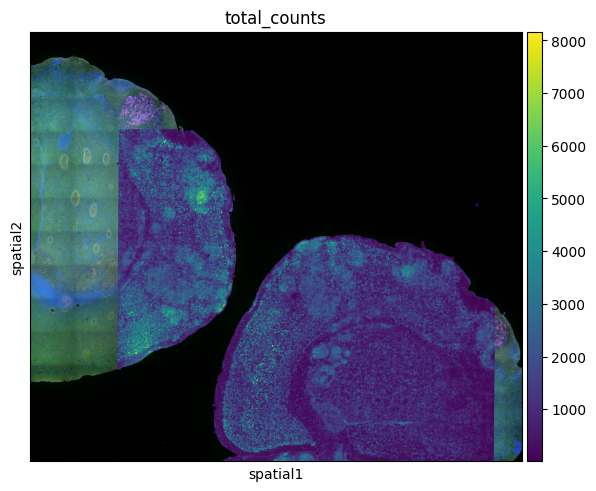

In [6]:
sc.pp.calculate_qc_metrics(adata_st, inplace=True)
sq.pl.spatial_scatter(adata_st, color="total_counts", size=1.5)
plt.savefig("spatial_total_counts_test.png",dpi=300,bbox_inches="tight")

# QC and normalization

In [7]:
sc.pp.calculate_qc_metrics(adata_st, inplace=True)

Spatial QC — plot metrics on tissue

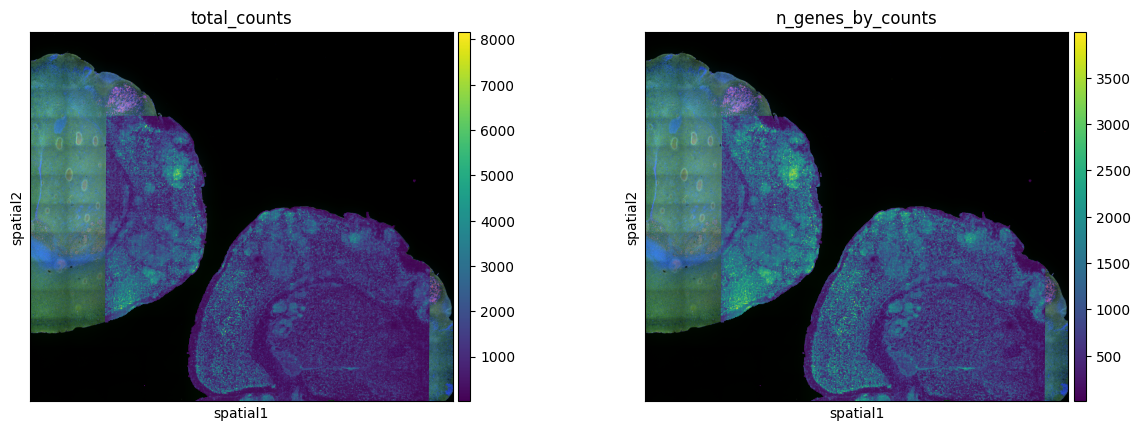

In [8]:
sq.pl.spatial_scatter(adata_st, color=["total_counts", "n_genes_by_counts"], size=1.5)

Filter low-quality spots

In [9]:
sc.pp.filter_cells(adata_st, min_counts=500)
sc.pp.filter_genes(adata_st, min_cells=10)

Stash raw counts

In [10]:
adata_st.layers["counts"] = adata_st.X.copy()
sc.pp.normalize_total(adata_st, target_sum=1e4)
sc.pp.log1p(adata_st)

# Spatially variable gene detection

spatial statistics

In [11]:
sq.gr.spatial_neighbors(adata_st, coord_type="grid", n_neighs=6)

Moran's I — spatial autocorrelation per gene

In [12]:
sq.gr.spatial_autocorr(
    adata_st,
    mode="moran",
    n_perms=100,
    n_jobs=4,
)

  0%|          | 0/100 [00:00<?, ?/s]

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planni

Top spatially variable genes

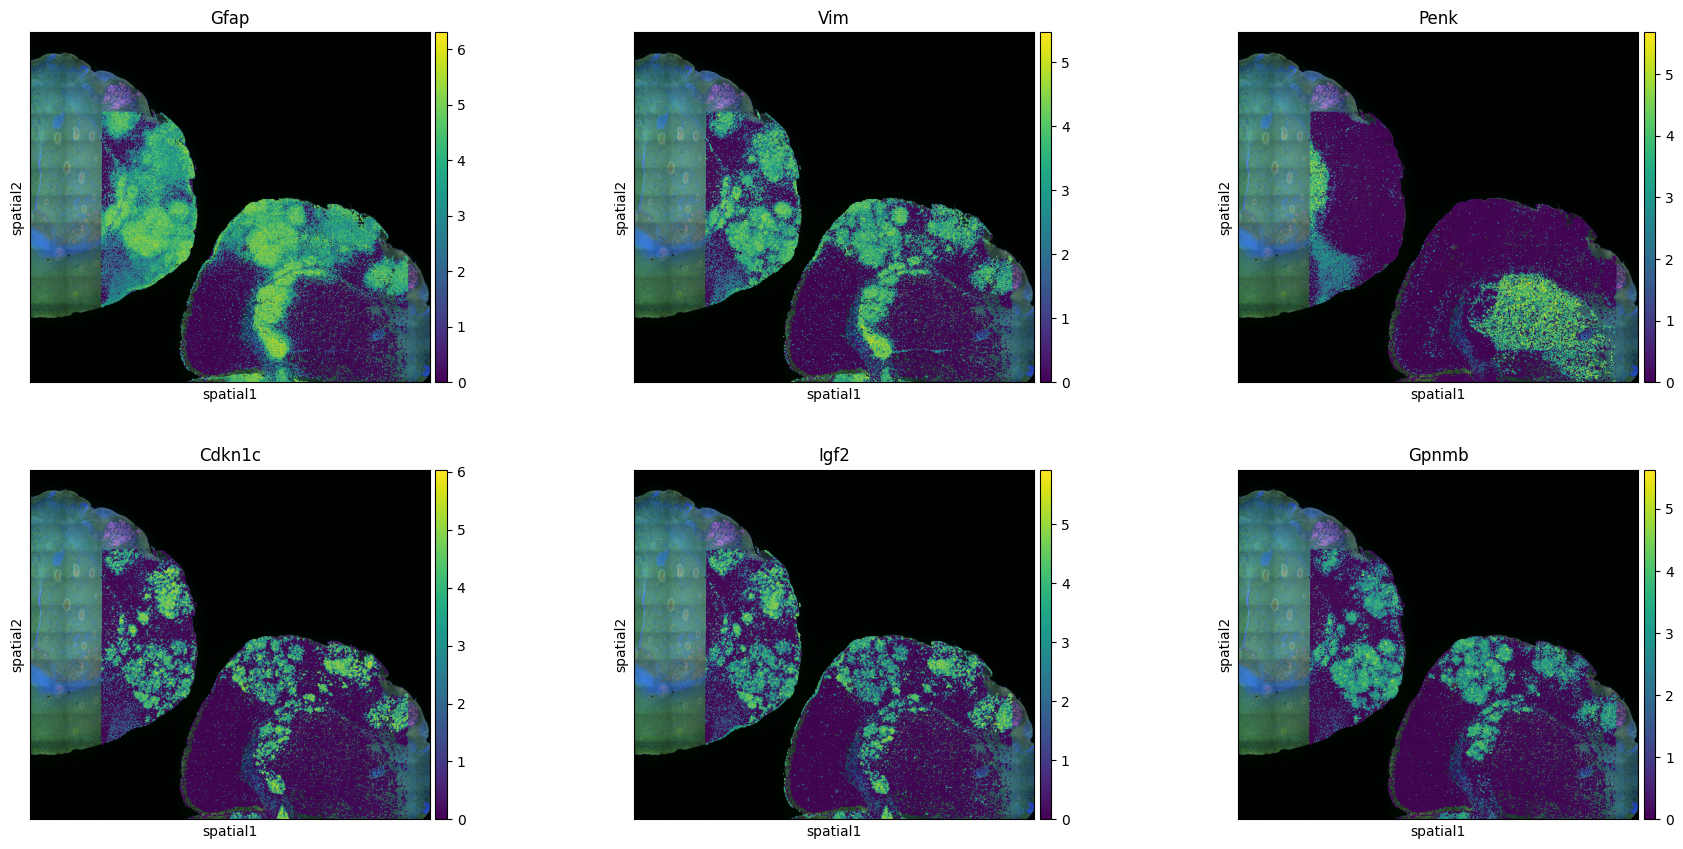

In [13]:
svg = adata_st.uns["moranI"].sort_values("I", ascending=False)
top_svgs = svg.head(6).index.tolist()
sq.pl.spatial_scatter(adata_st, color=top_svgs, size=1.5, ncols=3)

In [14]:
#adata_st.write_h5ad("spatial_3356629_D49_D1_16um_test.h5ad")

In [15]:
adata_st

AnnData object with n_obs × n_vars = 91573 × 15608
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatial', 'log1p', 'spatial_neighbors', 'moranI'
    obsm: 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [2]:
adata_st = sc.read_h5ad("spatial_3356629_D49_D1_16um_test.h5ad")

In [19]:
#91573 total spots pixels
#adata_st
#print(adata_st.X.max()) 
adata_st.layers["lognorm"] = adata_st.X.copy()

In [21]:
adata_st.write_h5ad("spatial_3356629_D49_D1_16um_test.h5ad")

In [4]:
adata_sc = adata_st[adata_st.obs['cell_type'] != 'unknown'].copy()

KeyError: 'cell_type'

In [22]:
adata_st.obs

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,n_counts
s_016um_00107_00066-1,1,107,66,589,6.380123,721.0,6.582025,22.468793,32.177531,46.047157,87.656033,721.0
s_016um_00126_00213-1,1,126,213,1963,7.582738,3159.0,8.058328,20.322887,26.622349,35.580880,53.687876,3159.0
s_016um_00290_00411-1,1,290,411,611,6.416732,726.0,6.588926,18.732782,29.614325,43.388430,84.710744,726.0
s_016um_00242_00130-1,1,242,130,570,6.347389,697.0,6.548219,22.668580,32.568149,46.915352,89.956958,697.0
s_016um_00230_00364-1,1,230,364,677,6.519147,822.0,6.712956,20.072993,29.805353,41.970803,78.467153,822.0
...,...,...,...,...,...,...,...,...,...,...,...,...
s_016um_00412_00400-1,1,412,400,1646,7.406711,2294.0,7.738488,13.251962,20.008718,29.729730,50.043592,2294.0
s_016um_00185_00374-1,1,185,374,1205,7.095064,1480.0,7.300473,12.635135,19.459459,32.094595,52.364865,1480.0
s_016um_00361_00190-1,1,361,190,1198,7.089243,1568.0,7.358194,16.964286,24.107143,36.352041,55.484694,1568.0
s_016um_00323_00266-1,1,323,266,743,6.612041,911.0,6.815640,17.782656,28.759605,40.395170,73.326015,911.0
